# PhishGuard: Exploratory Data Analysis

**Dataset:** `data/processed/features.csv`, 50,000 URLs (25,000 phishing, 25,000 legitimate) with 31 features from `src/features.py`.

**Goals of this notebook**
1. Check data quality: types, missing values, duplicates, constant features.
2. Class balance and source composition.
3. Distributions of the features per class.
4. Outliers.
5. Correlations, redundant features and the most informative features.
6. Check for shortcut features (bias) before modelling.
7. Write down the decisions for the preprocessing pipeline.

Every figure is also saved to `reports/figures/` for the report.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Validated colour-blind-safe pair: legitimate = blue, phishing = orange.
LEGIT, PHISH = "#2a78d6", "#eb6834"
PALETTE = {"Legitimate": LEGIT, "Phishing": PHISH}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ec8a89", "#b22d2d"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110, "savefig.dpi": 160,
    "font.family": "DejaVu Sans",
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

df = pd.read_csv(ROOT / "data" / "processed" / "features.csv")
df["class"] = df["label"].map({0: "Legitimate", 1: "Phishing"})
META = ["url", "label", "class", "source", "domain", "first_seen"]
FEATURES = [c for c in df.columns if c not in META]
NUMERIC = [c for c in FEATURES if c != "tld"]
BINARY = [c for c in NUMERIC if set(df[c].unique()) <= {0, 1}]
CONTINUOUS = [c for c in NUMERIC if c not in BINARY]
print(f"rows: {len(df):,} | features: {len(FEATURES)} "
      f"({len(CONTINUOUS)} continuous/count, {len(BINARY)} binary, 1 categorical)")
df.head()

rows: 50,000 | features: 31 (20 continuous/count, 10 binary, 1 categorical)


,url,label,source,domain,first_seen,url_length,hostname_length,path_length,query_length,num_dots,...,has_port,has_at_symbol,has_double_slash_in_path,hyphen_in_domain,brand_outside_domain,is_shortener,is_free_hosting,suspicious_tld,tld,class
0,https://privatez.link/portal/abuse/takedown-am...,0,tranco+crawler,privatez.link,NaN,51,13,30,0,1,...,0,0,0,0,0,0,0,1,link,Legitimate
1,http://ledger-ets.pages.dev,1,openphish,pages.dev,2026-10-23T00:00:12Z,27,20,0,0,2,...,0,0,0,0,0,0,1,0,dev,Phishing
2,https://signer.docusign.maccesshub.com/2d8bef1...,1,openphish,maccesshub.com,2026-10-19T00:00:08Z,75,30,37,0,3,...,0,0,0,0,0,0,0,0,com,Phishing
3,https://tye67d8uigtyc768iojhgtywe67898d7yujh.p...,1,phishtank,pages.dev,2024-10-07T13:02:11+00:00,77,46,1,21,2,...,0,0,0,0,0,0,1,0,dev,Phishing
4,https://constructingexcellence.org.uk/events/c...,0,tranco+crawler,constructingexcellence.org.uk,NaN,74,29,37,0,2,...,0,0,0,0,0,0,0,0,uk,Legitimate


## 1. Data quality: types, missing values, duplicates, constant features

In [2]:
quality = pd.DataFrame({
    "dtype": df[FEATURES].dtypes.astype(str),
    "missing": df[FEATURES].isna().sum(),
    "unique_values": df[FEATURES].nunique(),
})
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Total missing values in features:", int(quality["missing"].sum()))
print("Constant features (1 unique value):", quality.index[quality["unique_values"] == 1].tolist())
print("Rare binary features (true in < 1% of rows):",
      {c: int(df[c].sum()) for c in BINARY if df[c].mean() < 0.01})
quality.sort_values("unique_values")

Duplicate URLs: 0
Total missing values in features: 0
Constant features (1 unique value): []
Rare binary features (true in < 1% of rows): {'has_ip_host': 163, 'has_port': 30, 'has_at_symbol': 402, 'has_double_slash_in_path': 89, 'is_shortener': 130}


,dtype,missing,unique_values
has_double_slash_in_path,int64,0,2
hyphen_in_domain,int64,0,2
brand_outside_domain,int64,0,2
is_shortener,int64,0,2
is_https,int64,0,2
has_ip_host,int64,0,2
suspicious_tld,int64,0,2
is_free_hosting,int64,0,2
has_port,int64,0,2
has_at_symbol,int64,0,2


In [3]:
df[CONTINUOUS].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
url_length,50000.0,55.51,54.76,12.00,17.00,43.00,271.00,1436.00
hostname_length,50000.0,20.24,10.83,4.00,6.00,17.00,61.00,109.00
path_length,50000.0,18.69,27.36,0.00,0.00,12.00,112.00,1345.00
query_length,50000.0,8.59,45.64,0.00,0.00,0.00,194.01,1393.00
num_dots,50000.0,2.14,1.19,1.00,1.00,2.00,6.00,59.00
num_hyphens,50000.0,1.40,2.57,0.00,0.00,0.00,12.00,50.00
num_underscores,50000.0,0.18,1.12,0.00,0.00,0.00,4.00,124.00
num_slashes,50000.0,3.47,1.45,2.00,2.00,3.00,8.00,68.00
num_digits,50000.0,5.00,12.95,0.00,0.00,0.00,61.00,632.00
digit_ratio,50000.0,0.06,0.10,0.00,0.00,0.00,0.39,0.78


**Findings**
- No missing values and no duplicate URLs. Every feature can be computed from any valid URL. The pipeline will still have a `SimpleImputer`, to protect the apps against unusual input.
- No feature is constant. Some binary flags are **rare**: `has_port` is true for only 30 URLs (25 of them phishing, e.g. `rnfzd3.com:8989/register.html`), and IP hosts, `//` in the path and URL shorteners are also under 1%. They're rare but almost always mean phishing. **Decision: keep them.**
- The count features have long right tails (the max is far above the 99th percentile). These are covered in the outliers section.

## 2. Class balance and source composition

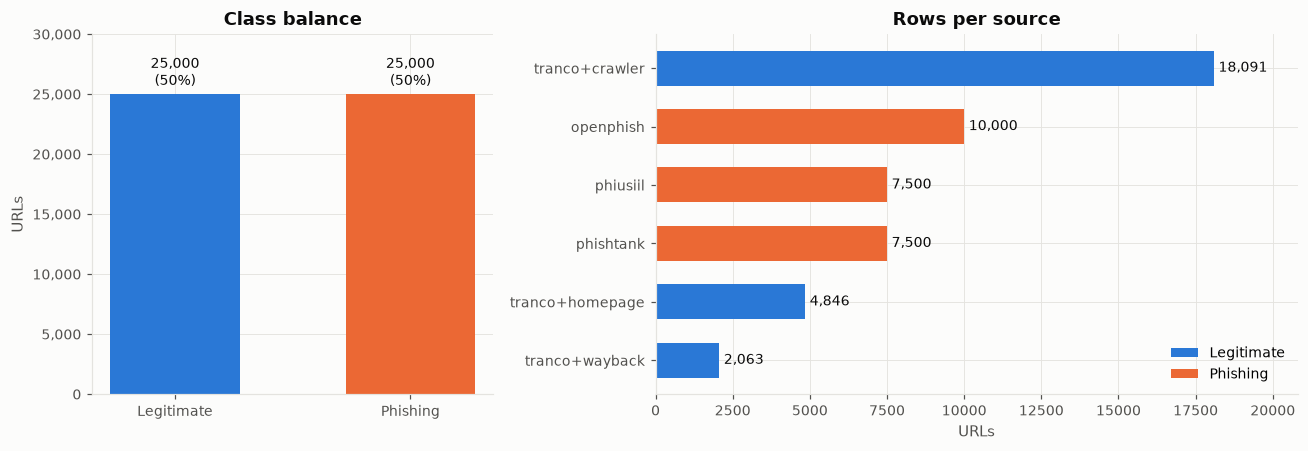

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})

counts = df["class"].value_counts().reindex(["Legitimate", "Phishing"])
bars = axes[0].bar(counts.index, counts.values, color=[LEGIT, PHISH], width=0.55)
axes[0].bar_label(bars, labels=[f"{v:,}\n({v/len(df):.0%})" for v in counts.values], color=INK, fontsize=9, padding=3)
axes[0].set_title("Class balance")
axes[0].set_ylabel("URLs")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

src = df.groupby(["source", "class"]).size().unstack(fill_value=0)
src = src.loc[src.sum(axis=1).sort_values().index]
y = np.arange(len(src))
for cls, color in PALETTE.items():
    b = axes[1].barh(y, src[cls], color=color, height=0.6, label=cls)
    axes[1].bar_label(b, labels=[f"{v:,}" if v else "" for v in src[cls]], color=INK, fontsize=9, padding=3)
axes[1].set_yticks(y, src.index)
axes[1].set_title("Rows per source")
axes[1].set_xlabel("URLs")
axes[1].set_xlim(0, src.values.max() * 1.15)
axes[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "01_class_balance_sources")

**Findings**
- The classes are exactly balanced (25,000 each), so accuracy isn't distorted by one big class and no resampling (SMOTE or class weights) is needed.
- Phishing comes from three sources and legitimate URLs from three collection methods, so no single source dominates its class.
- In real life phishing is rarer than 50%. We handle that with recall, precision, PR-AUC and threshold choice, not accuracy alone.

## 3. Distributions of the main numeric features per class

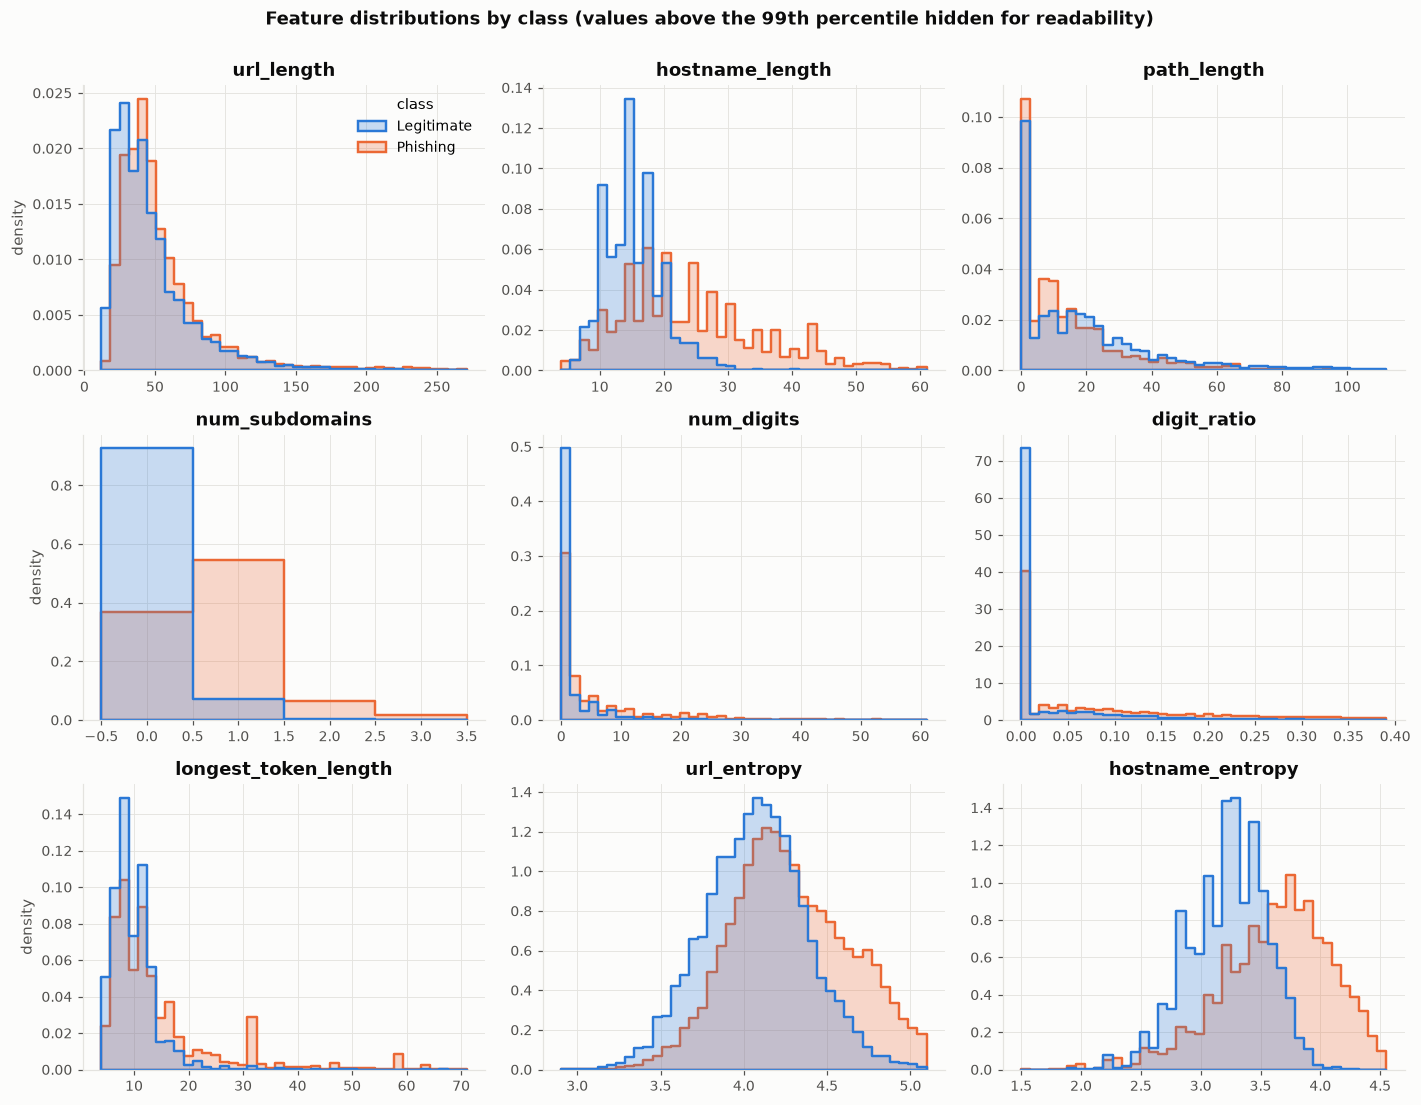

In [5]:
show = ["url_length", "hostname_length", "path_length", "num_subdomains", "num_digits",
        "digit_ratio", "longest_token_length", "url_entropy", "hostname_entropy"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.flat, show):
    hi = df[col].quantile(0.99)  # clip the long tail for display only
    data = df[df[col] <= hi]
    discrete = df[col].nunique() < 25
    sns.histplot(data=data, x=col, hue="class", palette=PALETTE, stat="density", common_norm=False,
                 element="step", fill=True, alpha=0.25, linewidth=1.6,
                 bins=None if discrete else 40, discrete=discrete, ax=ax, legend=(ax is axes.flat[0]))
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("density" if ax in axes[:, 0] else "")
fig.suptitle("Feature distributions by class (values above the 99th percentile hidden for readability)",
             fontsize=12, fontweight="bold", color=INK, y=1.0)
fig.tight_layout()
save(fig, "02_feature_distributions")

In [6]:
summary = df.groupby("class")[CONTINUOUS].median().T
summary["mean_legit"] = df[df.label == 0][CONTINUOUS].mean()
summary["mean_phish"] = df[df.label == 1][CONTINUOUS].mean()
summary["skewness"] = df[CONTINUOUS].skew()
summary.rename(columns={"Legitimate": "median_legit", "Phishing": "median_phish"}).round(2)

class,median_legit,median_phish,mean_legit,mean_phish,skewness
url_length,40.00,46.00,48.72,62.31,8.12
hostname_length,15.00,23.00,15.32,25.16,2.00
path_length,15.00,10.00,21.56,15.82,8.37
query_length,0.00,0.00,3.78,13.40,11.52
num_dots,2.00,2.00,1.90,2.38,6.34
num_hyphens,0.00,1.00,1.54,1.26,4.19
num_underscores,0.00,0.00,0.17,0.20,34.26
num_slashes,3.00,3.00,3.52,3.43,3.83
num_digits,0.00,2.00,2.19,7.82,8.59
digit_ratio,0.00,0.05,0.03,0.09,1.96


**Findings**
- **Hostname length, subdomain count and hostname entropy** are clearly shifted for phishing: fake hosts are longer, have more subdomains and look more random.
- **Digits** appear more often in phishing URLs (random IDs and generated domains).
- **Hyphens:** the median is 0 for legitimate and 1 for phishing (`hbl-secure-login`), but the legitimate mean is higher, because news and shop pages use long hyphenated slugs (`/news/budget-2026-explained`).
- **Path length** overlaps a lot between the classes. That's expected after the path-bias fix in data collection.
- Most count features are strongly right-skewed (skewness well above 1).

## 4. Outliers

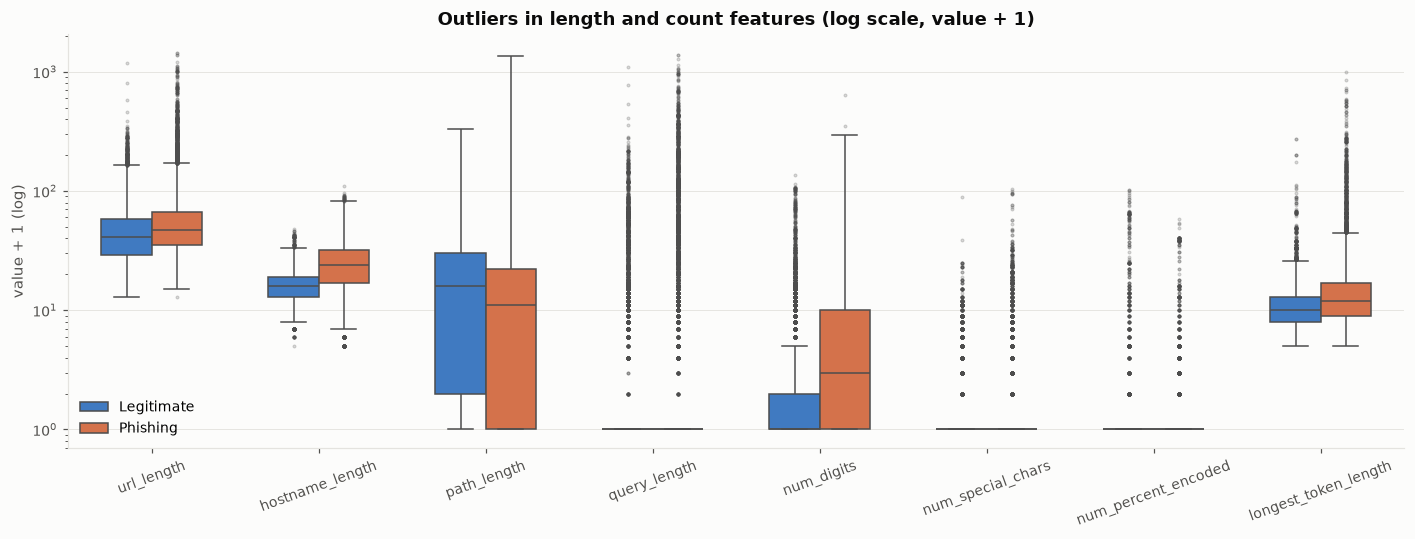

In [7]:
outlier_cols = ["url_length", "hostname_length", "path_length", "query_length", "num_digits",
                "num_special_chars", "num_percent_encoded", "longest_token_length"]
long = df.melt(id_vars="class", value_vars=outlier_cols, var_name="feature", value_name="value")
long["value"] = long["value"] + 1  # log scale needs values > 0

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=long, x="feature", y="value", hue="class", palette=PALETTE, log_scale=True,
            width=0.6, fliersize=1.5, linewidth=1, flierprops={"alpha": 0.3}, ax=ax)
ax.set_title("Outliers in length and count features (log scale, value + 1)")
ax.set_xlabel("")
ax.set_ylabel("value + 1 (log)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="")
fig.tight_layout()
save(fig, "03_outliers_boxplot")

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1)))

rows = []
for col in outlier_cols:
    flag = iqr_outliers(df[col])
    rows.append({"feature": col, "outliers": int(flag.sum()), "share": flag.mean(),
                 "phishing_share_among_outliers": df.loc[flag, "label"].mean(), "max": df[col].max()})
out = pd.DataFrame(rows).set_index("feature")
out.style.format({"outliers": "{:,}", "share": "{:.1%}", "phishing_share_among_outliers": "{:.1%}", "max": "{:,.0f}"})

,outliers,share,phishing_share_among_outliers,max
feature,,,,
url_length,"3,350",6.7%,61.1%,"1,436"
hostname_length,"3,087",6.2%,99.4%,109
path_length,"2,590",5.2%,31.8%,"1,345"
query_length,"6,371",12.7%,61.7%,"1,393"
num_digits,"5,610",11.2%,82.8%,632
num_special_chars,"6,870",13.7%,61.9%,102
num_percent_encoded,"1,221",2.4%,54.7%,100
longest_token_length,"4,351",8.7%,91.4%,996


In [9]:
print("Longest URLs in the dataset:")
for _, r in df.nlargest(5, "url_length")[["class", "url_length", "url"]].iterrows():
    print(f"  {r['class']:<10} {r['url_length']:>5}  {r['url'][:110]}...")

Longest URLs in the dataset:
  Phishing    1436  https://u24148341.ct.sendgrid.net/ls/click?upn=8pfxiuiO8W7wUsRV9a-2FeErFdpa-2BVEZiYEk-2FnSSW3IQpdvcn6K2HZVUvtP...
  Phishing    1428  https://u31696126.ct.sendgrid.net/ls/click?upn=qdcrpvzmiwdekw-2fpajfl35hskkhkes8t868-2fscecb8wsxfuki19ignipiar...
  Phishing    1375  https://login.myerowitzlaw.com/p/SUO49IRO3Lkt1g1OBSx7vQBXplHWSEIS7MtY8DHB5LZOQT8H96LCpLyy_TAjWsUBj94gluibJpVok...
  Phishing    1370  https://flat-bread-04ca.cloudflareaccess.com/cdn-cgi/access/login/vertiv-command-center.pages.dev?kid=617efb6e...
  Phishing    1202  https://hasgoodtools.com/l/TFXxpwdh0V0rcHBvw8TkW/link?token=eyJpdiI6IkZucEY1Mk9yd3JKVEdnVFJLWEFudFE9PSIsInZhbH...


**Findings**
- Every length and count feature has many statistical outliers (IQR rule), for example very long URLs with tracking parameters or long encoded strings.
- These outliers are **real URLs, not errors**. Long, encoded or parameter-heavy URLs are often exactly what phishing looks like. Removing them would throw away signal and make the model fail on such links in the app.

**Decisions**
- **Keep the outliers**; don't delete rows.
- For distance and linear models (KNN, Logistic Regression), apply a `log1p` transform to the skewed count features and then `StandardScaler`, so a few huge values don't dominate the distances and weights.
- Tree models (Random Forest, Gradient Boosting) aren't affected by outliers or scale.

## 5. Binary indicator features: how often each is true per class

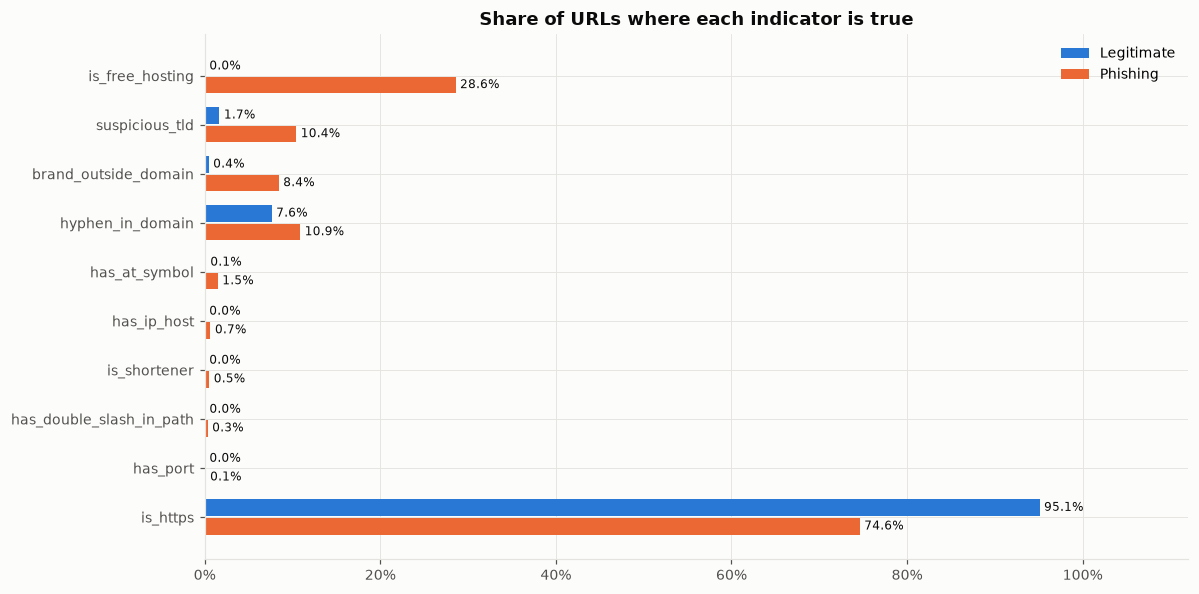

In [10]:
rates = df.groupby("class")[BINARY].mean().T
rates = rates.loc[(rates["Phishing"] - rates["Legitimate"]).sort_values().index]
y = np.arange(len(rates))
fig, ax = plt.subplots(figsize=(11, 5.5))
h = 0.38
for i, (cls, color) in enumerate(PALETTE.items()):
    b = ax.barh(y + (0.5 - i) * h, rates[cls], height=h - 0.04, color=color, label=cls)
    ax.bar_label(b, labels=[f"{v:.1%}" for v in rates[cls]], color=INK, fontsize=8, padding=3)
ax.set_yticks(y, rates.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1.12)
ax.set_title("Share of URLs where each indicator is true")
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "04_binary_feature_rates")

**Findings**
- **Free hosting** (28.6% of phishing vs almost 0% of legitimate) and **suspicious TLD** (10.4% vs 1.7%) are strong phishing signs.
- **`brand_outside_domain`** (a brand name in a URL that isn't the brand's real domain) appears in 8.4% of phishing vs 0.4% of legitimate URLs, about 20× more often.
- **HTTPS** is true for 95% of legitimate URLs but also for 74% of phishing. HTTPS is a weak signal, not proof of safety.
- IP-address hosts, `@`, ports and URL shorteners are rare (under 2%) but appear almost only in phishing.
- **Bias check:** free hosting is 0% in the legitimate class because our legitimate sample came from Tranco domains, and real sites on `github.io` or `blogspot.com` are missing. The model may over-trust this feature. **This is a known limitation**, to be checked in error analysis.

## 6. Top-level domains (TLD) per class

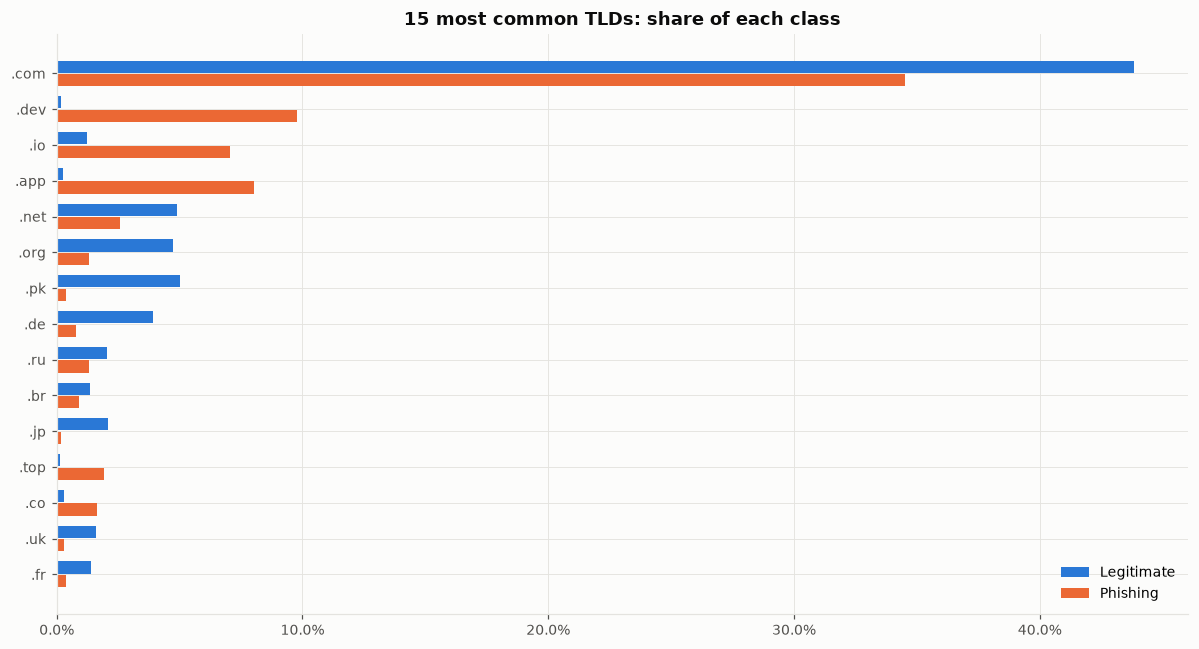

Distinct TLDs: 392
TLDs used by fewer than 20 URLs: 236


In [11]:
top = df["tld"].value_counts().head(15).index
tld = (df[df["tld"].isin(top)].groupby(["tld", "class"]).size().unstack(fill_value=0)
       .div(df["class"].value_counts(), axis=1))
tld = tld.loc[tld.sum(axis=1).sort_values().index]
y = np.arange(len(tld))
fig, ax = plt.subplots(figsize=(11, 6))
h = 0.38
for i, (cls, color) in enumerate(PALETTE.items()):
    ax.barh(y + (0.5 - i) * h, tld[cls], height=h - 0.04, color=color, label=cls)
ax.set_yticks(y, "." + tld.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("15 most common TLDs: share of each class")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "05_top_tlds")
print("Distinct TLDs:", df["tld"].nunique())
print("TLDs used by fewer than 20 URLs:", int((df["tld"].value_counts() < 20).sum()))

**Findings**
- `.com` is the most common TLD in both classes, so the TLD alone can't decide.
- `.dev` (2,448 vs 40), `.app` (2,009 vs 69), `.io`, `.top` and `.co` lean strongly towards phishing. Free hosting platforms like `pages.dev` and `vercel.app` use these endings.
- `.net`, `.org`, `.de`, `.jp`, `.uk` and `.fr` lean towards legitimate.
- **`.pk` (1,250 legitimate vs 99 phishing) after the `.pk` fix.** The first build had 5,774 vs 20, because Pakistani sites were over-sampled (23% of legitimate URLs, compared with about 0.2% of the Tranco top-1M). The model could have learned ".pk = always safe", but hacked Pakistani sites (e.g. on `.org.pk` and `.edu.pk`) do host phishing. **Fix:** `.pk` capped at 5% of legitimate URLs, and all 99 `.pk` phishing URLs in our sources included. `.pk` still leans legitimate (12.6 : 1), so in modelling we compare the model with and without `tld` and test hand-made `.pk` phishing.
- There are many rare TLDs. **Decision:** one-hot encode `tld` with `min_frequency` (rare TLDs grouped into "infrequent") and `handle_unknown="ignore"`, so a TLD never seen in training doesn't crash the app.

## 7. Correlations and redundant features

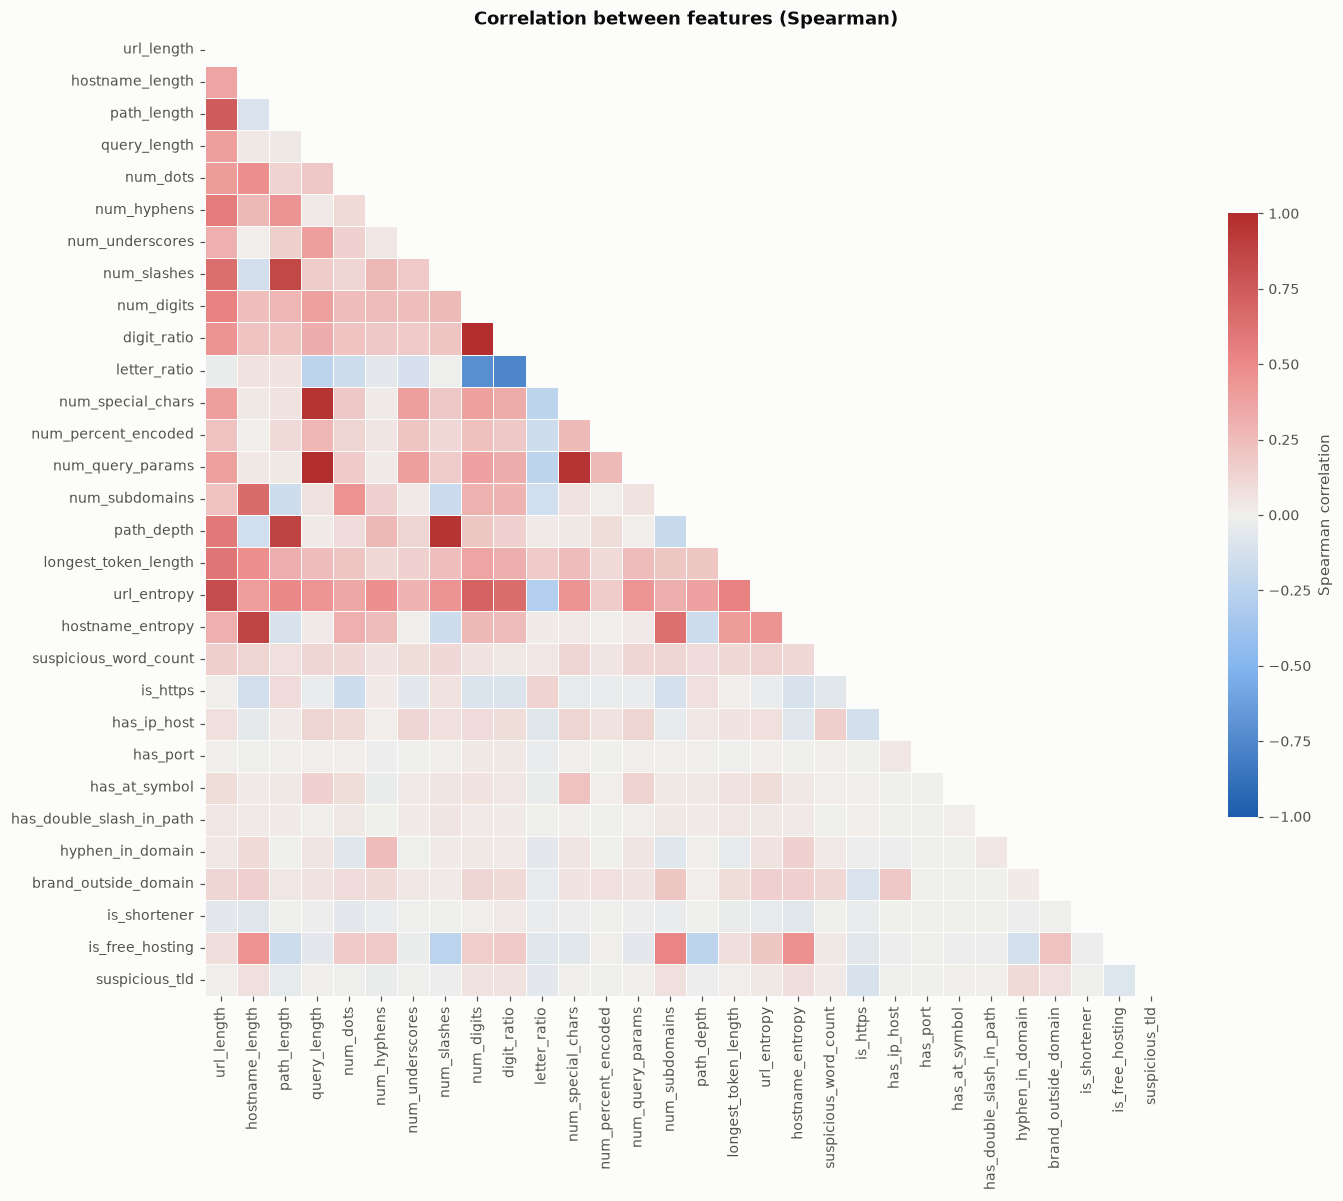

Highly correlated pairs (|r| >= 0.8):


,a,b,r
393,num_query_params,query_length,0.998
278,digit_ratio,num_digits,0.985
401,num_query_params,num_special_chars,0.965
333,num_special_chars,query_length,0.963
457,path_depth,num_slashes,0.963
452,path_depth,path_length,0.875
541,hostname_entropy,hostname_length,0.873
212,num_slashes,path_length,0.852
510,url_entropy,url_length,0.822


In [12]:
corr = df[NUMERIC].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.4, linecolor=SURFACE, cbar_kws={"shrink": 0.6, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between features (Spearman)")
ax.grid(False)
fig.tight_layout()
save(fig, "06_correlation_heatmap")

pairs = (corr.where(~mask).stack().reset_index().rename(columns={"level_0": "a", "level_1": "b", 0: "r"}))
pairs = pairs[pairs["r"].abs() >= 0.8].sort_values("r", key=abs, ascending=False)
print("Highly correlated pairs (|r| >= 0.8):")
pairs.round(3)

**Findings**
- Pairs with |r| ≥ 0.8 are listed above. They measure almost the same thing: length features with each other, digits with digit ratio, path length with path depth and slashes, and query length with query parameters.
- Highly correlated features mainly hurt **Logistic Regression** (unstable coefficients) and add little for trees.

**Decision:** keep all features for now. Tree models handle redundancy, and Logistic Regression uses L2 regularization, which spreads the weight across correlated features. During modelling we'll compare permutation importances and drop features that add nothing.

## 8. Which features carry the most information about the label?

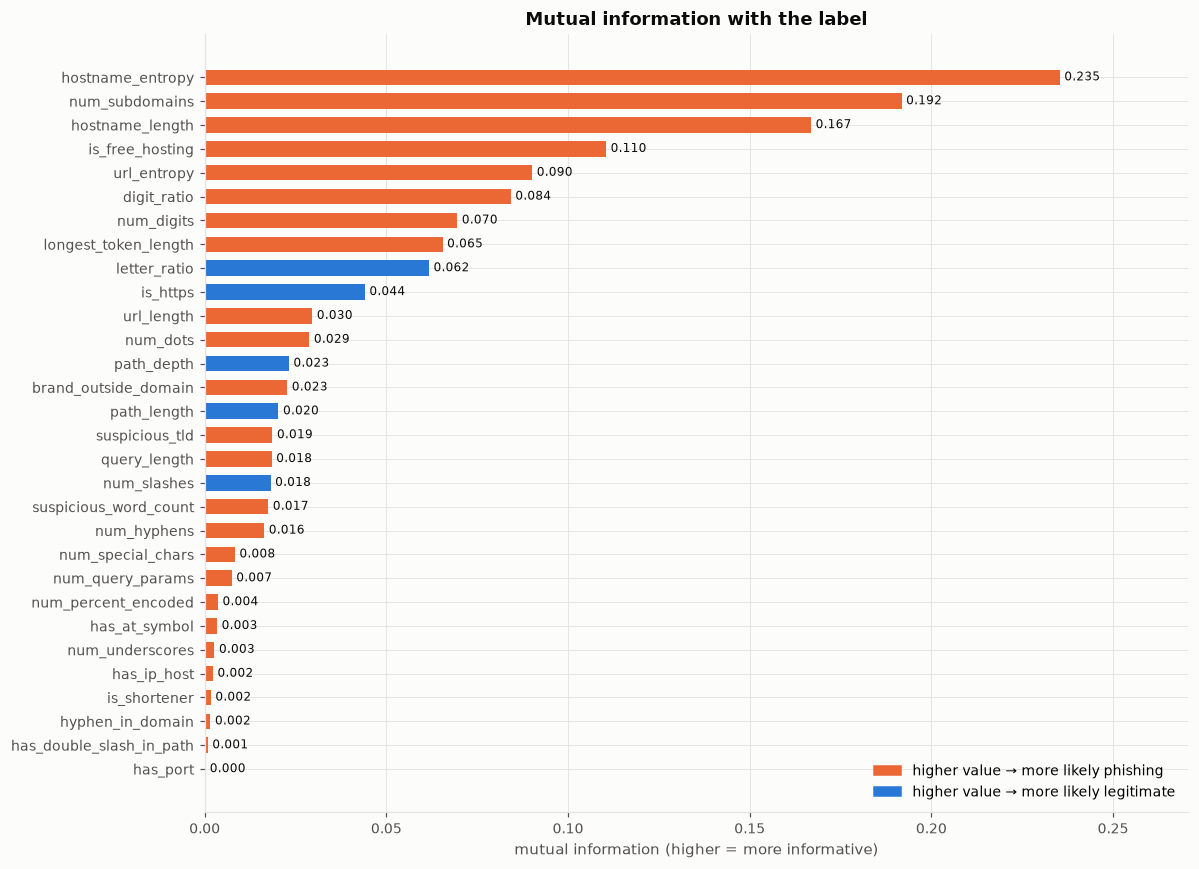

,mutual_information,spearman_with_label
hostname_entropy,0.235,0.480
num_subdomains,0.192,0.585
hostname_length,0.167,0.466
is_free_hosting,0.110,0.408
url_entropy,0.090,0.298
digit_ratio,0.084,0.354
num_digits,0.070,0.344
longest_token_length,0.065,0.239
letter_ratio,0.062,-0.209
is_https,0.044,-0.286


In [13]:
X = df[NUMERIC]
mi = pd.Series(mutual_info_classif(X, df["label"], discrete_features=[c in BINARY for c in X.columns], random_state=0),
               index=X.columns)
spear = X.corrwith(df["label"], method="spearman")
rank = pd.DataFrame({"mutual_information": mi, "spearman_with_label": spear}).sort_values("mutual_information")

fig, ax = plt.subplots(figsize=(11, 8))
colors = [PHISH if r > 0 else LEGIT for r in rank["spearman_with_label"]]
b = ax.barh(rank.index, rank["mutual_information"], color=colors, height=0.65)
ax.bar_label(b, labels=[f"{v:.3f}" for v in rank["mutual_information"]], color=INK, fontsize=8, padding=3)
ax.set_title("Mutual information with the label")
ax.set_xlabel("mutual information (higher = more informative)")
ax.set_xlim(0, rank["mutual_information"].max() * 1.15)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PHISH, label="higher value → more likely phishing"),
                   Patch(color=LEGIT, label="higher value → more likely legitimate")], loc="lower right")
fig.tight_layout()
save(fig, "07_mutual_information")
rank.sort_values("mutual_information", ascending=False).round(3).head(12)

**Findings**
- The most informative features are **real phishing signals**: hostname structure (subdomains, length, entropy), free hosting, digits and HTTPS. None of them is an artefact of how we collected the data.
- No single feature separates the classes on its own. The best mutual information is far below the maximum of ln 2 ≈ 0.69, so the model has to **combine** several signals. This is why the task isn't trivially easy.

## 9. Bias check: is the path-bias fix holding?

In [14]:
df["has_path"] = (df["path_depth"] > 0) | (df["query_length"] > 0)
mix = df.groupby(["class", "source"])["has_path"].agg(["mean", "size"]).rename(columns={"mean": "deep_link_share", "size": "rows"})
print(df.groupby("class")["has_path"].mean().map("{:.1%}".format).to_string())
mix.style.format({"deep_link_share": "{:.1%}", "rows": "{:,}"})

class
Legitimate    75.0%
Phishing      74.9%


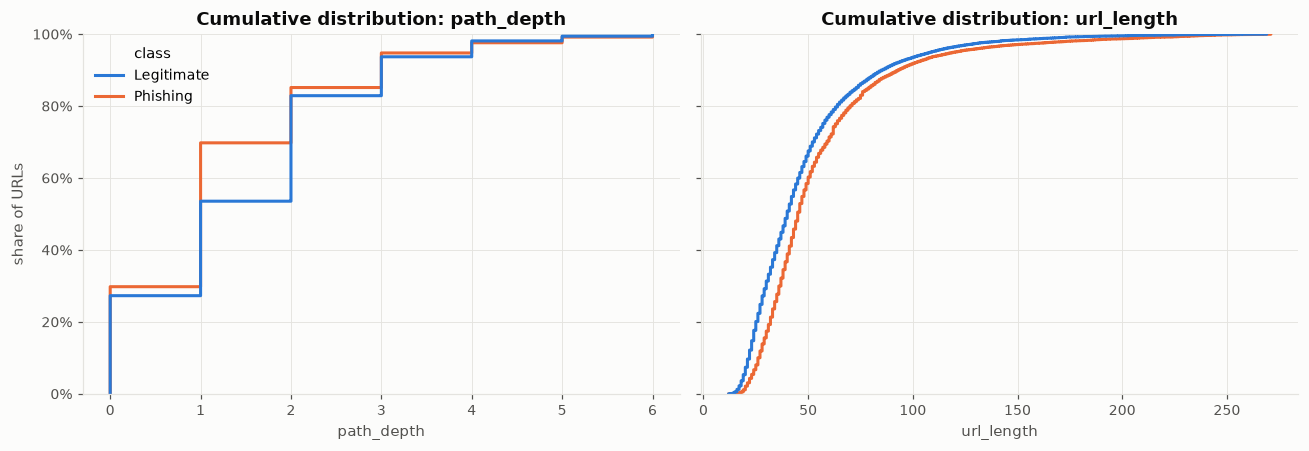

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col in zip(axes, ["path_depth", "url_length"]):
    data = df[df[col] <= df[col].quantile(0.99)]
    sns.ecdfplot(data=data, x=col, hue="class", palette=PALETTE, linewidth=2, ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"Cumulative distribution: {col}")
    ax.set_ylabel("share of URLs")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
fig.tight_layout()
save(fig, "08_bias_check_path")

**Findings**
- Both classes have 75% deep links and 25% bare homepages, so the shortcut "no path means phishing" is gone.
- The path-depth curves are close together, so path depth can't separate the classes on its own.
- URL length still differs (phishing is longer), which is a genuine phishing pattern (long hostnames, encoded parameters).

## 10. Time coverage (needed for the time-based test)

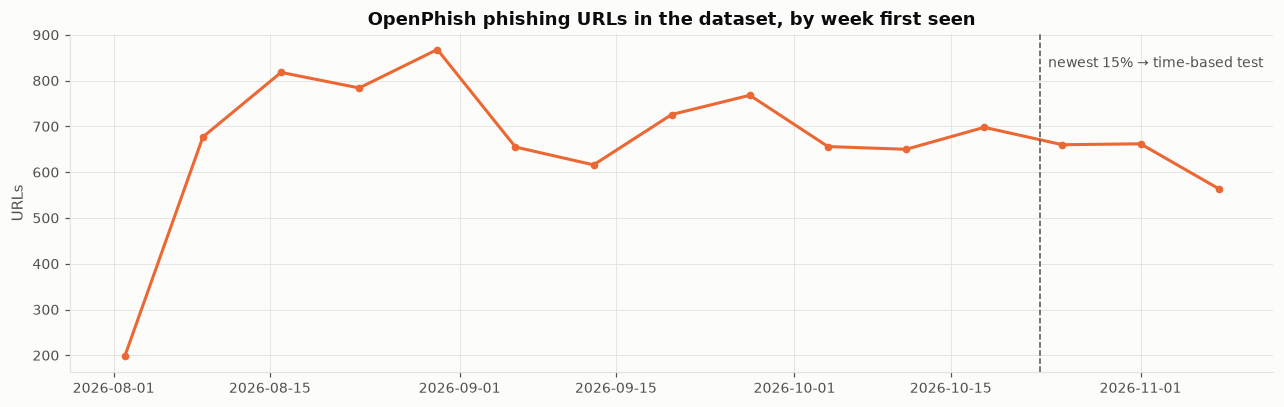

OpenPhish date range: 2026-08-01 to 2026-11-06
Cut-off for newest 15%: 2026-10-23
PhishTank date range: 2017-01-31 to 2026-11-06 | from 2026: 46%


In [16]:
dates = pd.to_datetime(df["first_seen"], errors="coerce", utc=True, format="ISO8601")
op = df.assign(date=dates)[df["source"] == "openphish"]
weekly = op.set_index("date").resample("W")["url"].count()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(weekly.index, weekly.values, color=PHISH, linewidth=2, marker="o", markersize=4)
ax.set_title("OpenPhish phishing URLs in the dataset, by week first seen")
ax.set_ylabel("URLs")
cut = op["date"].quantile(0.85)
ax.axvline(cut, color=INK2, linestyle="--", linewidth=1)
ax.text(cut, ax.get_ylim()[1] * 0.92, "  newest 15% → time-based test", color=INK2, fontsize=9)
fig.tight_layout()
save(fig, "09_openphish_timeline")
print("OpenPhish date range:", op["date"].min().date(), "to", op["date"].max().date())
print("Cut-off for newest 15%:", cut.date())
pt = dates[df["source"] == "phishtank"]
print("PhishTank date range:", pt.min().date(), "to", pt.max().date(), "| from 2026:", f"{(pt.dt.year == 2026).mean():.0%}")

**Findings**
- OpenPhish URLs cover August to November 2026 with steady weekly volume.
- Phishing URLs first seen after the cut-off (newest 15%) will be held out as a **"future phishing" test** to show the model works on newer scams than it was trained on.

## 11. Summary: decisions for the preprocessing pipeline

| Finding | Decision |
|---|---|
| No missing values | Keep `SimpleImputer` anyway, to protect the apps against unusual input |
| Rare binary flags (`has_port`, IP host, shortener) | Keep: rare but almost always phishing |
| Strong right skew and many outliers in counts and lengths | Keep the rows (they're real). Apply `log1p` and then `StandardScaler` for LR and KNN; trees use the raw values |
| Many rare TLDs | `OneHotEncoder(min_frequency=…, handle_unknown="ignore")` |
| Correlated length/count features | Keep for now; L2 regularization for LR; review with permutation importance |
| Classes exactly balanced | No resampling; report F1, recall, PR-AUC and the false-positive rate |
| Path bias removed (75% / 75%) | Nothing more needed |
| Free hosting is 0% in the legitimate class | Known limitation; check in error analysis |
| `.pk` still leans legitimate (1,250 vs 99, after the fix) | Compare the model with and without `tld`; test hand-made `.pk` phishing |
| Dated OpenPhish URLs | Newest 15% become the time-based test set |
| Same website could appear in train and test | Split grouped by `domain` |